# Optimizar la arquitectura de una red neuronal con Keras Tuner

Elaborado por: Alexander Fernández Pérez

## 0. Instalación e importaciones

In [ ]:
# pip install -q pandas matplotlib seaborn scikit-learn tensorflow keras-tuner tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout
import keras_tuner as kt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# Semilla fija: así los resultados se pueden repetir
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__, "| Keras Tuner:", kt.__version__)

TensorFlow: 2.21.0 | Keras Tuner: 1.4.8


## 1. Cargar e inspeccionar el nuevo dataset

**Breast Cancer Wisconsin:** 569 pacientes, 30 variables numéricas calculadas de imágenes de biopsias (radio, textura, área, etc. del núcleo celular).

En el original, `0 = maligno` y `1 = benigno`. se invierte para que, como en la clase con `diabetes`, `1` sea el caso de interés (cáncer maligno).

In [4]:
datos = load_breast_cancer(as_frame=True)
cancer_df = datos.frame.copy()
cancer_df["maligno"] = 1 - cancer_df["target"]   # 1 = maligno, 0 = benigno
cancer_df = cancer_df.drop(columns="target")

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,maligno
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Se revisa el balance de clases antes de entrenar.

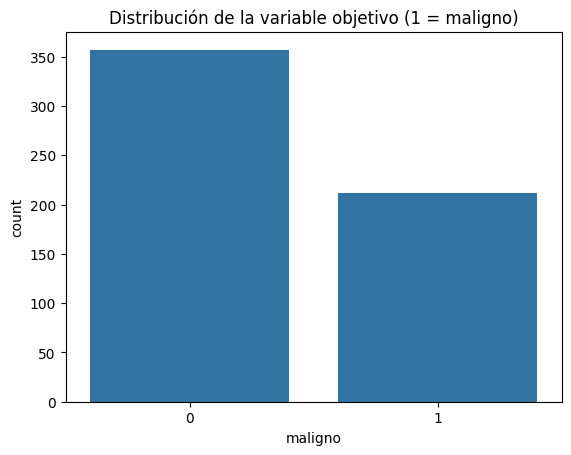

maligno
0    0.627
1    0.373
Name: proportion, dtype: float64


In [5]:
sns.countplot(data=cancer_df, x="maligno")
plt.title("Distribución de la variable objetivo (1 = maligno)")
plt.show()
print(cancer_df["maligno"].value_counts(normalize=True).round(3))

Algo desbalanceado, se usa `stratify` al dividir.

## 2. Preparar los datos

Se revisa tipos de datos y valores faltantes

In [6]:
cancer_df.info()
print("\nValores faltantes totales:", cancer_df.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

No hay valores faltantes ni ceros imposibles, así que no hace falta imputar

#### Rango de las variables

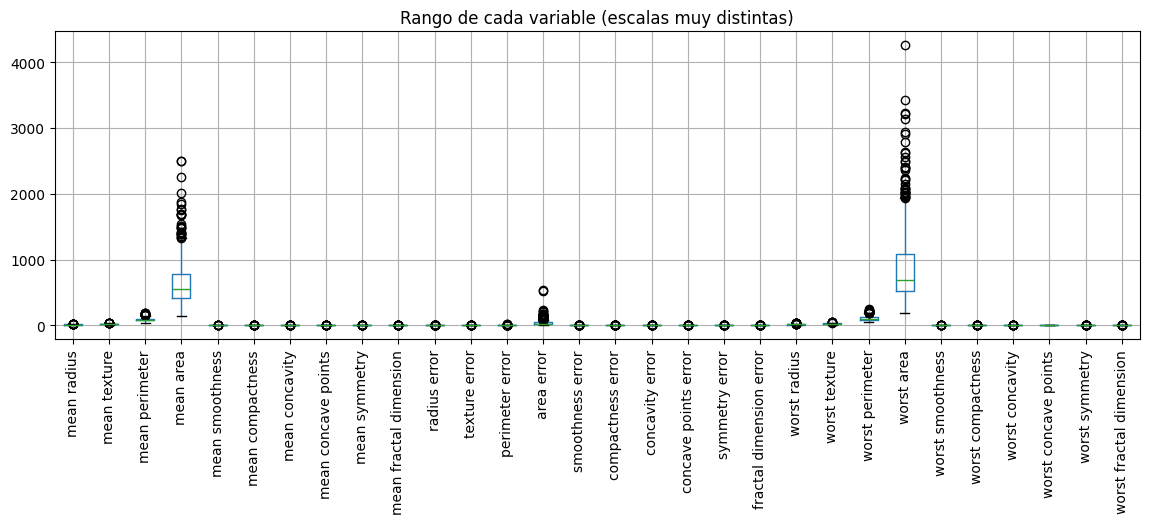

In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
cancer_df.drop(columns="maligno").boxplot(ax=ax)
plt.xticks(rotation=90)
plt.title("Rango de cada variable (escalas muy distintas)")
plt.show()

Las variables tienen escalas muy diferentes (por ejemplo `mean area` llega a 2500 y `mean smoothness` es 0.1).
Las redes neuronales aprenden mal con escalas tan distintas, así que se estandariza (media 0, desviación 1).

#### Correlaciones con el objetivo

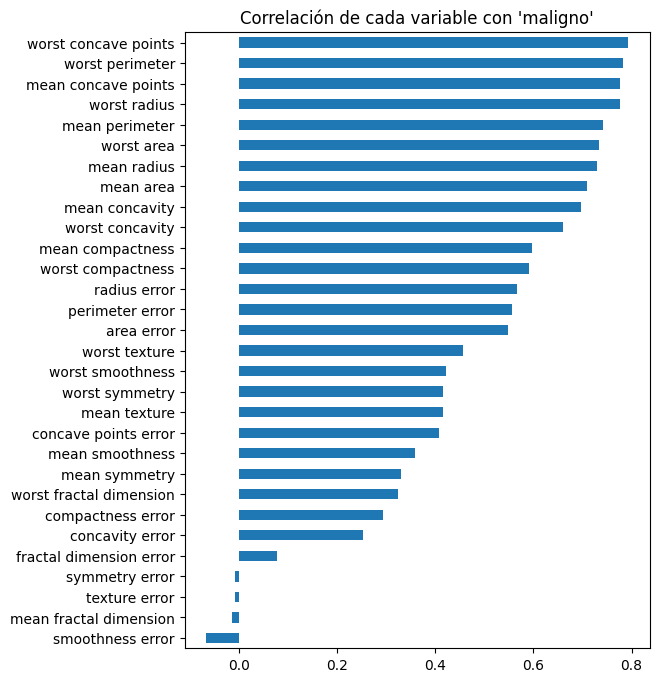

In [8]:
corr_objetivo = cancer_df.corr()["maligno"].drop("maligno").sort_values()
corr_objetivo.plot(kind="barh", figsize=(6, 8))
plt.title("Correlación de cada variable con 'maligno'")
plt.show()

Muchas variables (tamaño y forma del núcleo) se correlacionan fuerte con malignidad: es un problema donde una red debería funcionar bien.

#### Se separa `X` e `y`, y se divide en entrenamiento / validación / prueba

- **Entrenamiento (60%)**: para aprender los pesos.
- **Validación (20%)**: para que el tuner elija hiperparámetros y para el early stopping.
- **Prueba (20%)**: solo se usa al final, para comparar modelos de forma justa.

In [9]:
X = cancer_df.drop(columns="maligno")
y = cancer_df["maligno"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)  # 0.25 de 80% = 20%

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

Train: (341, 30) | Val: (114, 30) | Test: (114, 30)


#### Estandarizar

El `StandardScaler` se ajusta solo con entrenamiento y luego se aplica a validación y prueba (si no, se "filtra" información del test).

In [10]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

n_features = X_train_s.shape[1]
n_features

30

## 3. Red base (la misma arquitectura de la clase)

Se usa exactamente la red de clase: 12 → 8 → 1, ReLU, sigmoide, Adam, `binary_crossentropy` y el mismo early stopping (`patience=20`).
Así se tiene un punto de comparación (*baseline*).

In [11]:
tf.keras.utils.set_random_seed(SEED)

modelo_base = Sequential([
    tf.keras.Input(shape=(n_features,)),
    Dense(12, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid"),
])
modelo_base.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           372 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 485 (1.89 KB)

 Trainable params: 485 (1.89 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True)

hist_base = modelo_base.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=200, batch_size=32,
    callbacks=[early_stop], verbose=0)

print("Épocas entrenadas:", len(hist_base.history["loss"]))

Épocas entrenadas: 48


## 4. Búsqueda de hiperparámetros con Keras Tuner

En lugar de fijar a mano las capas y neuronas, se define un *espacio de búsqueda* y Keras Tuner prueba combinaciones, quedándose con la que tenga menor `val_loss`.

Hiperparámetros que se busca:

| Hiperparámetro | Valores probados |
|---|---|
| Número de capas ocultas | 1 a 3 |
| Neuronas por capa | 8 a 128 (de 8 en 8) |
| Función de activación | `relu`, `tanh` |
| Dropout por capa | 0.0 a 0.5 |
| Learning rate de Adam | 1e-4 a 1e-2 (escala logarítmica) |
| Batch size | 16, 32, 64 |

Se crea una clase `HyperModel` para poder buscar también el `batch_size` (que va en `fit`, no en el modelo).

In [13]:
class RedCancerHyperModel(kt.HyperModel):

    def build(self, hp):
        modelo = Sequential()
        modelo.add(tf.keras.Input(shape=(n_features,)))

        activacion = hp.Choice("activacion", ["relu", "tanh"])
        for i in range(hp.Int("n_capas", 1, 3)):
            modelo.add(Dense(hp.Int(f"neuronas_{i}", 8, 128, step=8),
                             activation=activacion))
            modelo.add(Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))

        modelo.add(Dense(1, activation="sigmoid"))

        lr = hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")
        modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                       loss="binary_crossentropy",
                       metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
        return modelo

    def fit(self, hp, modelo, *args, **kwargs):
        return modelo.fit(*args,
                          batch_size=hp.Choice("batch_size", [16, 32, 64]),
                          **kwargs)

Se usa `RandomSearch`: prueba 30 combinaciones al azar del espacio de búsqueda.
Es simple y, con pocos hiperparámetros, suele encontrar soluciones tan buenas como métodos más complejos.

In [14]:
tuner = kt.RandomSearch(
    RedCancerHyperModel(),
    objective="val_loss",       # lo que se quiere minimizar
    max_trials=30,              # número de combinaciones a probar
    executions_per_trial=1,
    seed=SEED,
    directory="keras_tuner",
    project_name="breast_cancer",
    overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 5
activacion (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
n_capas (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
neuronas_0 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 128, 'step': 8, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [15]:
tuner.search(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=200,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                restore_best_weights=True)],
    verbose=0,
)
print("Búsqueda terminada")


Búsqueda terminada


#### Mejores hiperparámetros encontrados

In [16]:
mejores_hp = tuner.get_best_hyperparameters(1)[0]
n_capas = mejores_hp.get("n_capas")

resumen_hp = {"n_capas": n_capas,
              "activacion": mejores_hp.get("activacion"),
              "learning_rate": round(mejores_hp.get("learning_rate"), 5),
              "batch_size": mejores_hp.get("batch_size")}
for i in range(n_capas):
    resumen_hp[f"neuronas_{i}"] = mejores_hp.get(f"neuronas_{i}")
    resumen_hp[f"dropout_{i}"] = mejores_hp.get(f"dropout_{i}")

pd.Series(resumen_hp, name="valor").to_frame()

,valor
n_capas,1
activacion,tanh
learning_rate,0.0057
batch_size,64
neuronas_0,128
dropout_0,0.4


Las 5 mejores combinaciones probadas (ordenadas por `val_loss`):

In [17]:
filas = []
for t in tuner.oracle.get_best_trials(5):
    fila = dict(t.hyperparameters.values)
    fila["val_loss"] = round(t.score, 4)
    filas.append(fila)
pd.DataFrame(filas)

,activacion,n_capas,neuronas_0,dropout_0,learning_rate,batch_size,neuronas_1,dropout_1,neuronas_2,dropout_2,val_loss
0,tanh,1,128,0.4,0.005704,64,32,0.0,40,0.4,0.0595
1,relu,3,96,0.0,0.001451,32,72,0.4,112,0.2,0.0599
2,relu,2,8,0.4,0.006311,32,8,0.4,80,0.2,0.0611
3,relu,3,72,0.1,0.000129,32,48,0.3,8,0.1,0.0614
4,relu,3,16,0.1,0.000739,16,72,0.1,72,0.1,0.0633


#### Reentrenar el mejor modelo

Se construye la red con los mejores hiperparámetros y se entrena desde cero, con early stopping y TensorBoard.

In [18]:
tf.keras.utils.set_random_seed(SEED)
modelo_opt = tuner.hypermodel.build(mejores_hp)
modelo_opt.summary()

log_dir = Path("logs/fit") / ("optimizado_" + datetime.now().strftime("%Y%m%d-%H%M%S"))
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                     restore_best_weights=True),
    tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
]

hist_opt = modelo_opt.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=200,
    batch_size=mejores_hp.get("batch_size"),
    callbacks=callbacks, verbose=0)

print("Épocas entrenadas:", len(hist_opt.history["loss"]))
print("Logs de TensorBoard en:", log_dir)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 63
Logs de TensorBoard en: logs\fit\optimizado_20261111-225357


Si quieres ver las curvas en TensorBoard (como en clase), ejecuta las dos celdas siguientes:

In [ ]:
%load_ext tensorboard

In [ ]:
%tensorboard --logdir logs/fit

## 5. Evaluar y comparar: red base vs. red optimizada

#### Curvas de aprendizaje

Si la curva de validación se separa mucho de la de entrenamiento, hay sobreajuste.

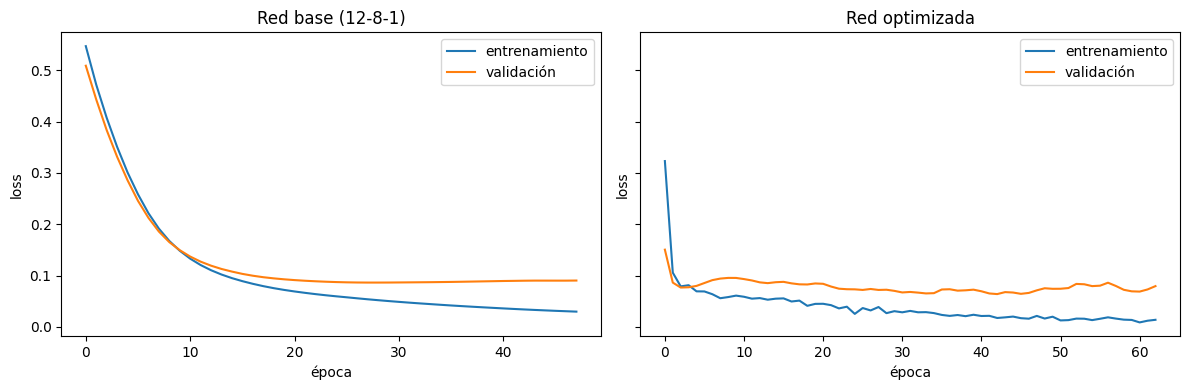

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nombre, h) in zip(axes, [("Red base (12-8-1)", hist_base),
                                  ("Red optimizada", hist_opt)]):
    ax.plot(h.history["loss"], label="entrenamiento")
    ax.plot(h.history["val_loss"], label="validación")
    ax.set_title(nombre); ax.set_xlabel("época"); ax.set_ylabel("loss")
    ax.legend()
plt.tight_layout(); plt.show()

#### Métricas en el conjunto de prueba

Además del *accuracy*, en un problema médico importa mucho el **recall** (de los tumores malignos, cuántos detecta el modelo): un falso negativo es el error más grave.

In [20]:
def metricas(modelo, X_, y_, umbral=0.5):
    prob = modelo.predict(X_, verbose=0).ravel()
    pred = (prob >= umbral).astype(int)
    return {"accuracy": accuracy_score(y_, pred),
            "precision": precision_score(y_, pred),
            "recall": recall_score(y_, pred),
            "f1": f1_score(y_, pred),
            "auc": roc_auc_score(y_, prob),
            "loss": modelo.evaluate(X_, y_, verbose=0)[0]}

comparacion = pd.DataFrame({
    "Base - train": metricas(modelo_base, X_train_s, y_train),
    "Base - val": metricas(modelo_base, X_val_s, y_val),
    "Base - test": metricas(modelo_base, X_test_s, y_test),
    "Optimizada - train": metricas(modelo_opt, X_train_s, y_train),
    "Optimizada - val": metricas(modelo_opt, X_val_s, y_val),
    "Optimizada - test": metricas(modelo_opt, X_test_s, y_test),
}).round(4)
comparacion

,Base - train,Base - val,Base - test,Optimizada - train,Optimizada - val,Optimizada - test
accuracy,0.9912,0.9649,0.9825,0.9971,0.9737,0.9737
precision,0.9921,0.9535,1.0000,1.0000,0.9545,0.9756
recall,0.9843,0.9535,0.9524,0.9921,0.9767,0.9524
f1,0.9881,0.9535,0.9756,0.9960,0.9655,0.9639
auc,0.9979,0.9925,0.9944,1.0000,0.9971,0.9927
loss,0.0525,0.0863,0.0940,0.0155,0.0638,0.1169


Brecha entre entrenamiento y prueba (mientras más grande, más sobreajuste):

In [21]:
brecha = pd.DataFrame({
    "Base": [comparacion.loc["accuracy", "Base - train"] - comparacion.loc["accuracy", "Base - test"],
             comparacion.loc["loss", "Base - test"] - comparacion.loc["loss", "Base - train"]],
    "Optimizada": [comparacion.loc["accuracy", "Optimizada - train"] - comparacion.loc["accuracy", "Optimizada - test"],
                   comparacion.loc["loss", "Optimizada - test"] - comparacion.loc["loss", "Optimizada - train"]],
}, index=["accuracy (train - test)", "loss (test - train)"]).round(4)
brecha

,Base,Optimizada
accuracy (train - test),0.0087,0.0234
loss (test - train),0.0415,0.1014


#### Matrices de confusión (prueba)

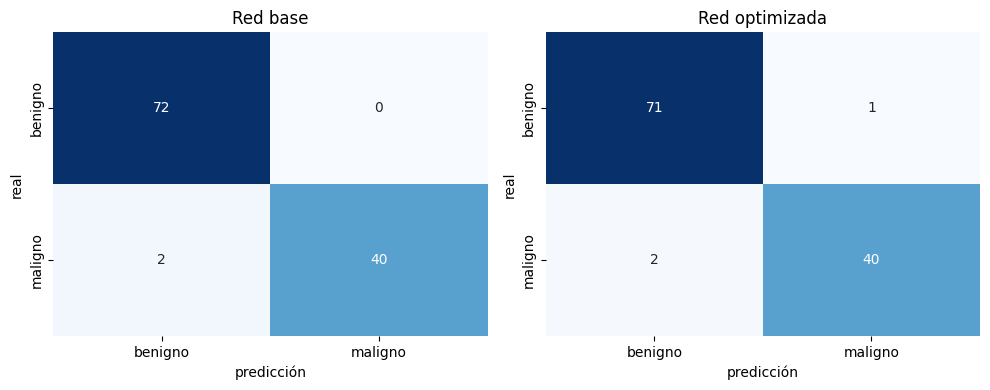

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, m) in zip(axes, [("Red base", modelo_base), ("Red optimizada", modelo_opt)]):
    pred = (m.predict(X_test_s, verbose=0).ravel() >= 0.5).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["benigno", "maligno"], yticklabels=["benigno", "maligno"], ax=ax)
    ax.set_title(nombre); ax.set_xlabel("predicción"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()

In [23]:
pred_opt = (modelo_opt.predict(X_test_s, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, pred_opt, target_names=["benigno", "maligno"]))

              precision    recall  f1-score   support

     benigno       0.97      0.99      0.98        72
     maligno       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



#### Comparación más robusta: validación cruzada (5 folds)

El test tiene solo 114 pacientes: **1 paciente = 0.88 puntos de accuracy**, así que una sola división puede engañar.
Para comparar mejor, entrenamos ambas arquitecturas en 5 particiones distintas (con los datos de train + val) y promediamos.

In [24]:
from sklearn.model_selection import StratifiedKFold

def crear_base():
    m = Sequential([tf.keras.Input(shape=(n_features,)),
                    Dense(12, activation="relu"), Dense(8, activation="relu"),
                    Dense(1, activation="sigmoid")])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m, 32

def crear_opt():
    return tuner.hypermodel.build(mejores_hp), mejores_hp.get("batch_size")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados = []
for fold, (idx_tr, idx_va) in enumerate(skf.split(X_temp, y_temp)):
    sc = StandardScaler().fit(X_temp.iloc[idx_tr])
    Xtr, Xva = sc.transform(X_temp.iloc[idx_tr]), sc.transform(X_temp.iloc[idx_va])
    ytr, yva = y_temp.iloc[idx_tr], y_temp.iloc[idx_va]
    for nombre, crear in [("Base", crear_base), ("Optimizada", crear_opt)]:
        tf.keras.utils.set_random_seed(SEED + fold)
        m, bs = crear()
        m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=bs, verbose=0,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                          restore_best_weights=True)])
        r = metricas(m, Xva, yva); r.update(modelo=nombre, fold=fold)
        resultados.append(r)

cv = pd.DataFrame(resultados)
cv.groupby("modelo")[["accuracy", "recall", "f1", "auc", "loss"]].agg(["mean", "std"]).round(4)

accuracy          recall              f1             auc          \
               mean     std    mean     std    mean     std    mean     std   
modelo                                                                        
Base         0.9736  0.0147  0.9588  0.0335  0.9643  0.0203  0.9935  0.0070   
Optimizada   0.9714  0.0184  0.9529  0.0446  0.9611  0.0258  0.9947  0.0062   

              loss          
              mean     std  
modelo                      
Base        0.0793  0.0420  
Optimizada  0.0650  0.0346

## 6. Hacer una predicción

Se toma una paciente del conjunto de prueba y comparamos la predicción con la etiqueta real.
Keras necesita una entrada 2D: `(1, n_features)`.

In [25]:
i = 10
paciente = X_test_s[i].reshape(1, n_features)

prob = modelo_opt.predict(paciente, verbose=0)[0, 0]
print(f"Probabilidad de maligno: {prob:.3f}")
print("Predicción de la red:", "maligno" if prob >= 0.5 else "benigno")
print("Etiqueta real:       ", "maligno" if y_test.iloc[i] == 1 else "benigno")

Probabilidad de maligno: 0.922
Predicción de la red: maligno
Etiqueta real:        maligno


## 7. Guardar y volver a cargar el modelo optimizado

In [26]:
modelo_opt.save("modelo_cancer_optimizado.keras")
modelo_cargado = load_model("modelo_cancer_optimizado.keras")

prob_cargado = modelo_cargado.predict(paciente, verbose=0)[0, 0]
print(f"Modelo recargado -> probabilidad: {prob_cargado:.3f} ->",
      "maligno" if prob_cargado >= 0.5 else "benigno")

Modelo recargado -> probabilidad: 0.922 -> maligno


## 8. Respuestas de la actividad

**a. ¿Qué método de búsqueda de hiperparámetros usaste?**
- **Keras Tuner con `RandomSearch`**: 30 combinaciones al azar, eligiendo la que tuvo menor `val_loss` en el conjunto de validación.

**b. ¿Qué parámetros buscaste?**
- Número de capas ocultas (1–3), neuronas por capa (8–128), activación (`relu`/`tanh`), dropout por capa (0–0.5), learning rate de Adam (1e-4 a 1e-2, escala log) y batch size (16/32/64).
- **Mejor combinación:** 1 capa oculta de 128 neuronas, `tanh`, dropout 0.4, learning rate ≈ 0.0057, batch size 64 (4 097 parámetros vs. 485 de la red base).

**c. ¿Cómo se comparan las métricas de la red optimizada con la red base?**

| | Red base (12-8-1) | Red optimizada |
|---|---|---|
| Validación – loss / accuracy | 0.086 / 96.5% | **0.064 / 97.4%** |
| Prueba – accuracy | **98.2%** | 97.4% |
| Prueba – recall (malignos) | 95.2% | 95.2% |
| Prueba – AUC | **0.994** | 0.993 |
| Validación cruzada 5 folds – accuracy | 97.4% ± 1.5 | 97.1% ± 1.8 |
| Validación cruzada 5 folds – AUC | 0.994 | **0.995** |
| Validación cruzada 5 folds – loss | 0.079 | **0.065** |

- La red optimizada mejoró en validación (que es lo que el tuner optimiza), pero en prueba no superó a la base: la diferencia en accuracy es de 1 paciente de 114. En validación cruzada quedan prácticamente empatadas (las diferencias son menores que la desviación estándar).
- La red optimizada sobreajusta un poco más: casi 100% en entrenamiento y mayor brecha train–test (2.3 vs 0.9 puntos de accuracy).
- Conclusión: en este dataset la red simple ya está cerca del techo (~97–98%). Lo que más mejora el resultado no es la arquitectura sino el preprocesamiento: estandarizar las variables (la red de la clase, sin escalar, llegaba a ~62% en diabetes). Además, elegir entre 30 modelos con un conjunto de validación pequeño (114 casos) hace que el "ganador" quede algo ajustado a esa validación.

**d. ¿Qué más probarías para mejorar las métricas o reducir el sobreajuste?**
- Usar validación cruzada dentro de la búsqueda (en vez de un solo conjunto de validación) para que el tuner no se ajuste a una sola partición.
- Probar Hyperband u Optuna (búsqueda bayesiana) y más trials, incluyendo regularización L2 y `BatchNormalization` en el espacio de búsqueda.
- Ajustar el umbral de decisión (por ejemplo < 0.5) para subir el recall de malignos, ya que un falso negativo es el error más grave.
- Usar `class_weight` por el leve desbalance de clases.
- Comparar con modelos más simples (regresión logística, random forest): en datos tabulares pequeños suelen igualar o superar a una red.